## Principle Component Analysis (PCA)
#### Linear Dimensionality Reduction

- Principal Components Analysis (PCA) is a way to find and use directions in the data space along which data samples vary the most.


<center><img src="img/fig77.png" width=500 height=500 /></center>

Assume samples have $D$ attributes.

We want to linearly project each sample to a smaller space,
of dimension $M$ such that as much information about each sample is maintained as possible.  

- One way to characterize the information is by the variance of the data.  

- We want the the projected data to have the maximum variance. 

Let's assume each sample $\xv_n$ **has zero mean**.  For $M=1$, we want
the direction vector (unit length) $\uv_1$ that maximizes the variance
of each projected sample. 

The projected variance along $\uv_1$  is
$$
\frac{1}{N} \sum_{n=1}^N (\uv_1^T \xv_n)^2 = \uv_1^T \Sv \uv_1
$$
where
$$
\Sv = \frac{1}{N} \sum_{n=1}^N \xv_n \xv_n^T
$$
To maximize the projectd variance $\uv_1^T \Sv \uv_1$, we have to solve the constrained optimization $\uv_1^T \Sv \uv_1$
subject to the constraint
$\uv_1^T \uv_1 = 1$.  

This constraint is added with a Lagrange
multipler so that we want $\uv_1$ that maximizes
$$
 \uv_1^T \Sv \uv_1+ \lambda_1(1-\uv_1^T \uv_1)
$$
Setting the derivative of this with respect to $\uv_1$ equal to zero we find
that
$$
\Sv \uv_1 = \lambda_1 \uv_1
$$


- This implies that $\lambda_1$ is an eigenvalue of the covariance matrix $\Sv$, with the associated eigenvector $\uv_1$.

- To maximize the projected variance, choose the largest eigenvalue of $\Sv$.

- The dominant eigenvector $\mathbf{u}_1$ specifies the direction of most 
variance, also called the first principal component.


Additional directions, all orthogonal to each other, are found by the
**eigendecomposition of $\Sv$**, or, equivalently, **the singular value
decomposition** of data sample matrix $\Xv$ with mean zero.  

### Singular Value Decomposition (SVD)

The Singular Value Decomposition (SVD) is the decomposition of a matrix $A$ of size
$m × n$ into:

$$A = U S V^T$$


where $U$ and $V$ are orthogonal matrices i.e., the inverse of the matrix is its transpose, so $U^TU=UU^T=I$, where $I$ is the identity matrix.
- $U$ is of size $m×m$; left singular vectors (eigenvectors of $AA^T$). 
- $V$ is of size $n×n$; right singular vectors (eigenvectors of $A^{T}A$). 
- $S$ is a diagonal matrix of size $m × n$, with the elements of this matrix, being known as singular values (eigenvalues of $A^{T}A$).
    - $σ_1 ≥σ_2 ≥ \dots ≥ 0 $


**The dot product of two orthogonal vectors equals zero.**
<center><img src="img/orth.png" width=200 height=200 /></center>

    X = X - np.mean(X,axis=0)
    U,s,V = np.linalg.svd(X)
    V = V.T
    
Then, to project onto the eigenvectors, just

    proj = X @ V

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import gzip
import pickle

In [3]:
with gzip.open('mnist.pkl.gz', 'rb') as f:
    train_set, valid_set, test_set = pickle.load(f, encoding='latin1')

Xtrain = train_set[0]
Ttrain = train_set[1].reshape((-1,1))

Xtest = test_set[0]
Ttest = test_set[1].reshape((-1,1))

Xtrain.shape, Ttrain.shape, Xtest.shape, Ttest.shape

((50000, 784), (50000, 1), (10000, 784), (10000, 1))

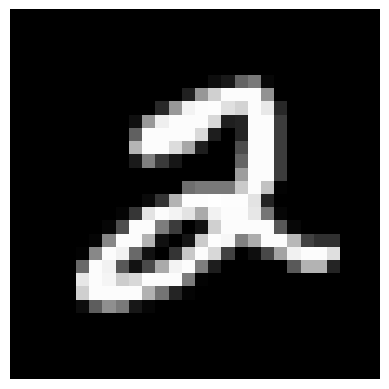

In [4]:
plt.imshow(Xtrain[5, :].reshape((28, 28)), cmap='gray')
plt.axis('off');

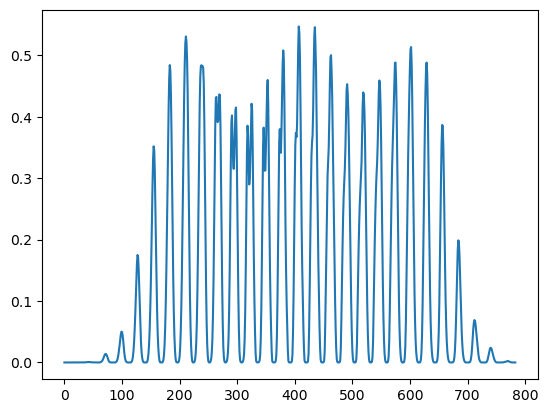

In [5]:
Xmean = Xtrain.mean(axis=0)
plt.plot(Xmean);

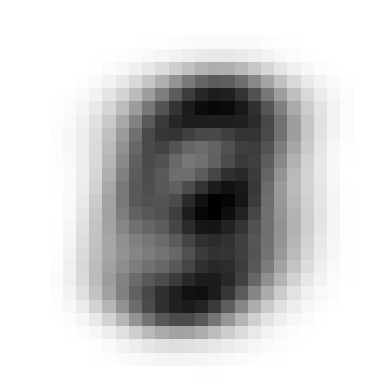

In [6]:
plt.imshow(-Xmean.reshape((28, 28)), cmap='gray')
plt.axis('off');

In [7]:
U, S, V = np.linalg.svd(Xtrain - Xmean, full_matrices=False)
V = V.T

In [ ]:
#Xtrain -= Xmean
#C = np.cov(Xtrain.T)
#evals,evecs = np.linalg.eig(C)
#indices = np.argsort(evals) 
#indices = indices[::-1]
#evecs = evecs[:,indices]
#evals = evals[indices]

In [8]:
print(f'{U.shape=}\n{S.shape=}\n{V.shape=}')

U.shape=(50000, 784)
S.shape=(784,)
V.shape=(784, 784)


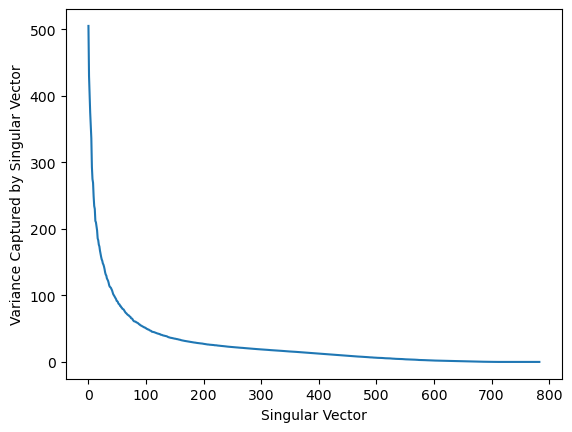

In [9]:
plt.plot(S)
plt.xlabel('Singular Vector')
plt.ylabel('Variance Captured by Singular Vector');

#### What do the first 16 singular vectors look like?

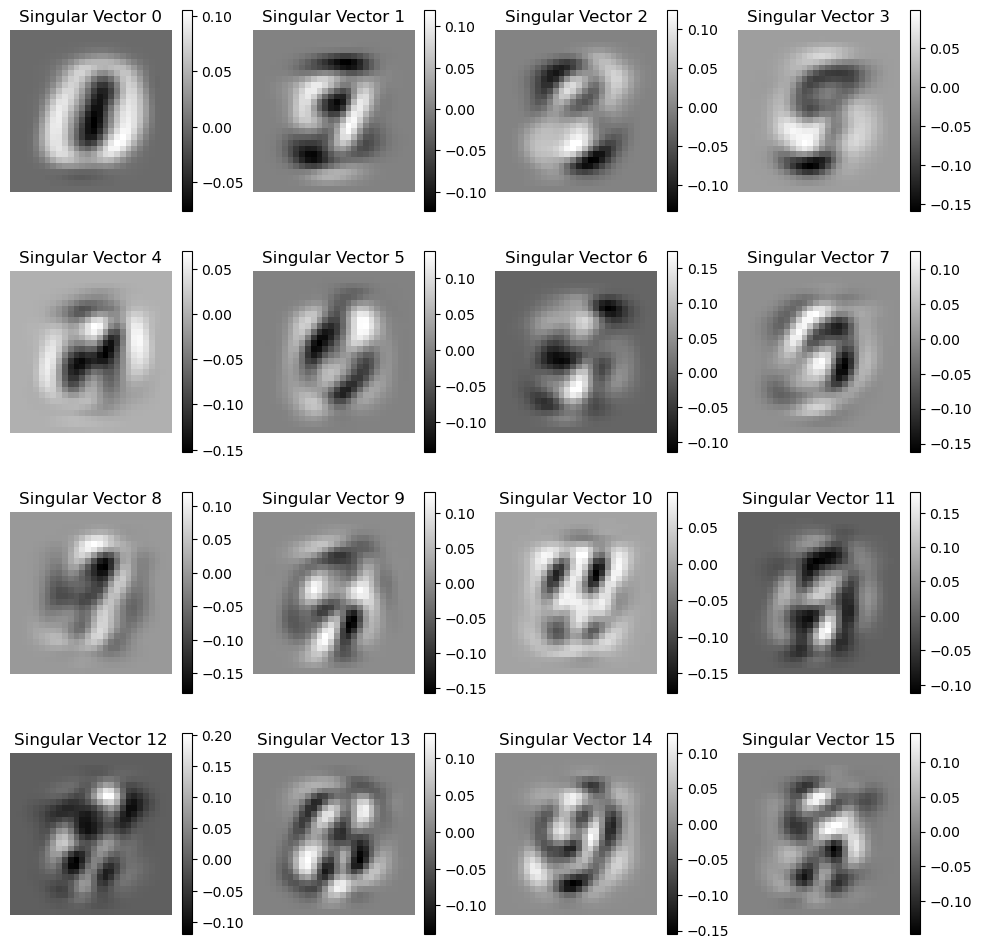

In [10]:
plt.figure(figsize=(12, 12))
for vi in range(16):
    plt.subplot(4, 4, vi + 1)
    plt.imshow(V[:, vi].reshape((28, 28)), cmap='gray')
    plt.title(f'Singular Vector {vi}')
    plt.axis('off')
    plt.colorbar()

#### How about the last 16?

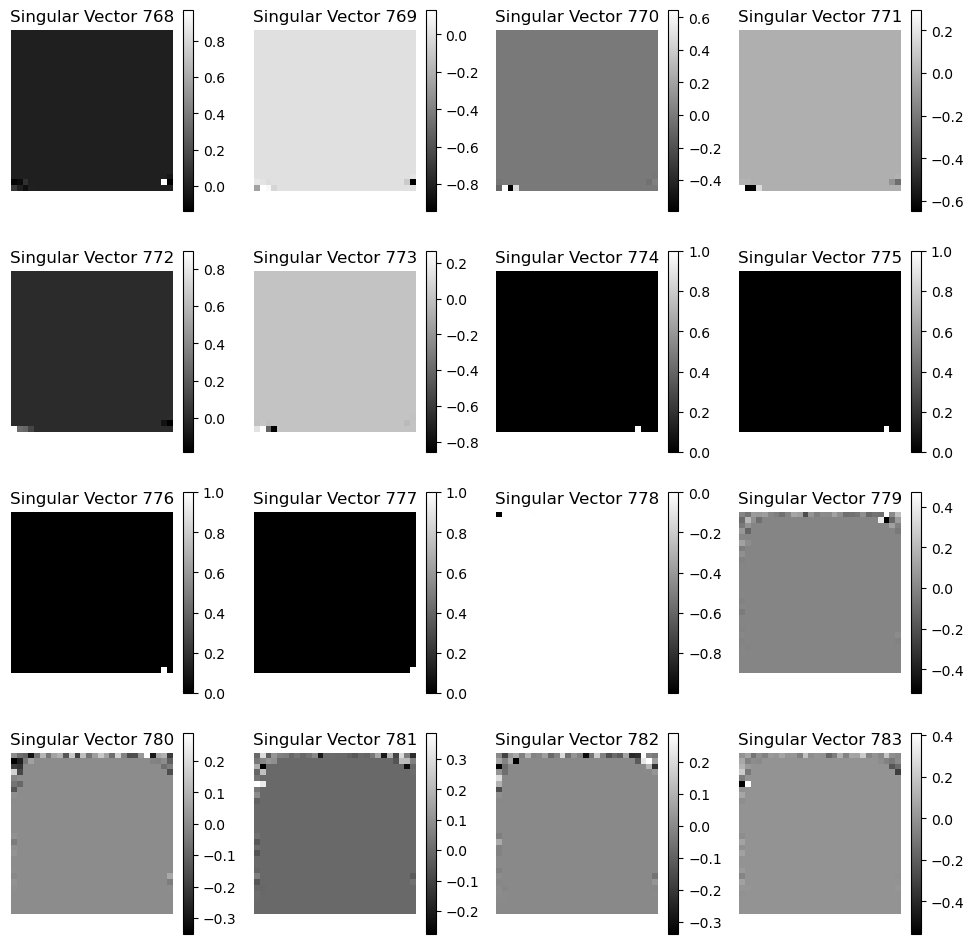

In [11]:
plt.figure(figsize=(12, 12))
for vi in range(16):
    plt.subplot(4, 4, vi + 1)
    plt.imshow(V[:, 784 - 16 + vi].reshape((28, 28)), cmap='gray')
    plt.title(f'Singular Vector {784 - 16 + vi}')
    plt.axis('off')
    plt.colorbar()

**We can check that two singular vectors are indeed orthogonal. Their dot product must be 0.**

In [12]:
V[:, 1].T @ V[:, 2]

np.float32(-4.1302353e-09)